# Pretrained MobileNetV2 Action Recognition

This notebook trains an action classifier using a pretrained MobileNetV2 model.

## NVIDIA GPU setup on Windows

TensorFlow 2.11 and newer do not use CUDA GPUs from a native Windows Python environment. To use the NVIDIA GPU, run this notebook in WSL2:

1. Install WSL2 and Ubuntu from an elevated PowerShell with `wsl --install -d Ubuntu`, then restart Windows if prompted.
2. Install the VS Code WSL extension and open this project folder in WSL (`/mnt/d/LIME`). Select a Python kernel created inside WSL, not the Windows `.venv`.
3. Run the install cell below in the WSL kernel. The Windows NVIDIA driver is used by WSL2; do not install a separate Linux NVIDIA display driver inside WSL.
4. Run the GPU setup cell. It stops with an error if TensorFlow cannot see and execute work on the GPU.

In [1]:
import platform
import subprocess
import sys

if platform.system() != 'Linux':
    raise RuntimeError(
        'Use a Linux/WSL2 Python kernel for NVIDIA CUDA support; native Windows TensorFlow cannot use this GPU.'
    )

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install',
    'tensorflow[and-cuda]', 'scikit-learn', 'matplotlib', 'pillow', 'numpy', 'opencv-python'
])

RuntimeError: Use a Linux/WSL2 Python kernel for NVIDIA CUDA support; native Windows TensorFlow cannot use this GPU.

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

print(f'TensorFlow version: {tf.__version__}')
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.22.0-rc0
GPU devices: []


In [3]:
gpu_devices = tf.config.list_physical_devices('GPU')

if not gpu_devices:
    raise RuntimeError(
        'No TensorFlow GPU found. Use the WSL2 Linux kernel and install tensorflow[and-cuda] as described above.'
    )

for gpu in gpu_devices:
    tf.config.experimental.set_memory_growth(gpu, True)

with tf.device('/GPU:0'):
    gpu_probe = tf.linalg.matmul(tf.ones((1, 1)), tf.ones((1, 1)))
if 'GPU:0' not in gpu_probe.device:
    raise RuntimeError(f'TensorFlow did not place its test operation on the GPU: {gpu_probe.device}')

print(f'GPU ready: {gpu_devices[0].name}')

RuntimeError: No TensorFlow GPU found. Use the WSL2 Linux kernel and install tensorflow[and-cuda] as described above.

In [4]:
# Dataset paths
dataset_root_candidates = [
    r'/mnt/d/LIME/VOCdevkit/VOC2012',
    r'/mnt/m/LIME/VOCdevkit/VOC2012',
    r'D:/LIME/VOCdevkit/VOC2012',
    r'm:/LIME/VOCdevkit/VOC2012',
    r'D:\LIME\VOCdevkit\VOC2012',
    r'm:\LIME\VOCdevkit\VOC2012'
]
dataset_root = next((p for p in dataset_root_candidates if os.path.exists(p)), dataset_root_candidates[0])

image_dir = os.path.join(dataset_root, 'JPEGImages')
action_dir = os.path.join(dataset_root, 'ImageSets', 'Action')
print(f'Dataset root: {dataset_root}')
print(f'Image directory: {image_dir}')
print(f'Action directory: {action_dir}')

action_classes = [
    'jumping', 'phoning', 'playinginstrument', 'reading', 'ridingbike',
    'ridinghorse', 'running', 'takingphoto', 'usingcomputer', 'walking'
]
print('Action classes:', action_classes)

Dataset root: D:/LIME/VOCdevkit/VOC2012
Image directory: D:/LIME/VOCdevkit/VOC2012\JPEGImages
Action directory: D:/LIME/VOCdevkit/VOC2012\ImageSets\Action
Action classes: ['jumping', 'phoning', 'playinginstrument', 'reading', 'ridingbike', 'ridinghorse', 'running', 'takingphoto', 'usingcomputer', 'walking']


In [5]:
def load_action_dataset(action_classes, image_dir, action_dir, target_size=(224, 224), limit_per_class=None):
    if not os.path.isdir(image_dir):
        raise FileNotFoundError(f'VOC image directory not found: {image_dir}')
    if not os.path.isdir(action_dir):
        raise FileNotFoundError(f'VOC Action annotation directory not found: {action_dir}')

    images = []
    labels = []

    for class_index, class_name in enumerate(action_classes):
        train_file = os.path.join(action_dir, f'{class_name}_train.txt')
        val_file = os.path.join(action_dir, f'{class_name}_val.txt')
        annotation_files = [path for path in (train_file, val_file) if os.path.isfile(path)]
        if not annotation_files:
            raise FileNotFoundError(f'No train/validation annotation files found for {class_name} in {action_dir}')

        seen = set()
        class_sample_count = 0
        for annotation_file in annotation_files:
            if limit_per_class is not None and class_sample_count >= limit_per_class:
                break
            with open(annotation_file, 'r', encoding='utf-8') as f:
                for line_number, line in enumerate(f, start=1):
                    fields = line.split()
                    if not fields:
                        continue
                    if len(fields) < 3:
                        raise ValueError(
                            f'Expected image id, instance id, and label in {annotation_file}:{line_number}; '
                            f'got {line.rstrip()!r}'
                        )

                    image_id, _, class_label = fields[:3]
                    if class_label != '1' or image_id in seen:
                        continue
                    seen.add(image_id)

                    img_path = os.path.join(image_dir, f'{image_id}.jpg')
                    if not os.path.isfile(img_path):
                        continue

                    img = load_img(img_path, target_size=target_size, color_mode='rgb')
                    arr = img_to_array(img)
                    # MobileNetV2 preprocessing scales RGB pixels from 0-255 to -1..1.
                    images.append(preprocess_input(arr))
                    labels.append(class_index)
                    class_sample_count += 1

                    if limit_per_class is not None and class_sample_count >= limit_per_class:
                        break

    if not images:
        raise ValueError(
            f'No positive VOC Action samples were loaded from {action_dir}. '
            'Check that the annotation files contain positive labels and matching JPEG images exist.'
        )

    return np.array(images, dtype='float32'), np.array(labels, dtype='int32')

X, y = load_action_dataset(action_classes, image_dir, action_dir, limit_per_class=None)
print(f'Loaded {len(X)} positive training samples across {len(action_classes)} action classes')
print(f'Example image shape: {X[0].shape}')
print('Label distribution:', {cls: int(np.sum(y == i)) for i, cls in enumerate(action_classes)})

Loaded 4087 positive training samples across 10 action classes
Example image shape: (224, 224, 3)
Label distribution: {'jumping': 405, 'phoning': 444, 'playinginstrument': 459, 'reading': 463, 'ridingbike': 400, 'ridinghorse': 411, 'running': 310, 'takingphoto': 414, 'usingcomputer': 395, 'walking': 386}


In [6]:
# Split into train/validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_train_cat = to_categorical(y_train, num_classes=len(action_classes))
y_val_cat = to_categorical(y_val, num_classes=len(action_classes))

print(f'Train samples: {len(X_train)}')
print(f'Validation samples: {len(X_val)}')

Train samples: 3269
Validation samples: 818


In [7]:
# Build the model on the GPU; TensorFlow keeps its model operations and variables there.
with tf.device('/GPU:0'):
    base_model = MobileNetV2(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(action_classes), activation='softmax')(x)

    mobilenet_model = keras.Model(inputs, outputs)
    mobilenet_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,918,986 (11.14 MB)

 Trainable params: 661,002 (2.52 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
# Optional data augmentation to improve generalization
data_generator = keras.preprocessing.image.ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_gen = data_generator.flow(
    X_train,
    y_train_cat,
    batch_size=32,
    shuffle=True
)
val_gen = data_generator.flow(
    X_val,
    y_val_cat,
    batch_size=32,
    shuffle=False
)

history = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    steps_per_epoch=max(1, len(X_train) // 32),
    validation_steps=max(1, len(X_val) // 32),
    verbose=1
)

mobilenet_model.save('pretrained_mobilenetv2_action_model.keras')
print('Saved MobileNetV2 model to pretrained_mobilenetv2_action_model.keras')

Epoch 1/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 94s 899ms/step - accuracy: 0.4297 - loss: 1.6855 - val_accuracy: 0.5913 - val_loss: 1.2559
Epoch 2/10
  1/102 ━━━━━━━━━━━━━━━━━━━━ 1:06 654ms/step - accuracy: 0.6875 - loss: 1.0586

d:\LIME\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 179ms/step - accuracy: 0.6875 - loss: 1.0586 - val_accuracy: 0.5925 - val_loss: 1.2788
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 90s 879ms/step - accuracy: 0.6166 - loss: 1.1517 - val_accuracy: 0.6100 - val_loss: 1.1700
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 183ms/step - accuracy: 0.7188 - loss: 1.1052 - val_accuracy: 0.6288 - val_loss: 1.1348
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 90s 885ms/step - accuracy: 0.6518 - loss: 1.0389 - val_accuracy: 0.6313 - val_loss: 1.1132
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 179ms/step - accuracy: 0.6562 - loss: 1.0396 - val_accuracy: 0.6162 - val_loss: 1.1072
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 89s 877ms/step - accuracy: 0.6886 - loss: 0.9525 - val_accuracy: 0.6388 - val_loss: 1.0732
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 178ms/step - accuracy: 0.5938 - loss: 0.9251 - val_accuracy: 0.6313 - val_loss: 1.1270
Epoch 9/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 90s 887ms/step - accuracy: 0.6963 - loss: 0.9009 - val

                   precision    recall  f1-score   support

          jumping       0.59      0.59      0.59        81
          phoning       0.63      0.58      0.61        89
playinginstrument       0.77      0.82      0.79        92
          reading       0.82      0.58      0.68        93
       ridingbike       0.75      0.76      0.76        80
      ridinghorse       0.80      0.90      0.85        82
          running       0.58      0.50      0.54        62
      takingphoto       0.63      0.48      0.55        83
    usingcomputer       0.71      0.89      0.79        79
          walking       0.34      0.45      0.39        77

         accuracy                           0.66       818
        macro avg       0.66      0.66      0.65       818
     weighted avg       0.67      0.66      0.66       818

Confusion matrix:
[[48  2  1  0  6  1  8  1  0 14]
 [ 1 52  4  5  1  2  1  8  5 10]
 [ 1  3 75  2  0  0  0  3  6  2]
 [ 1  8  7 54  1  1  0  2 16  3]
 [ 4  2  1  0 61  1  

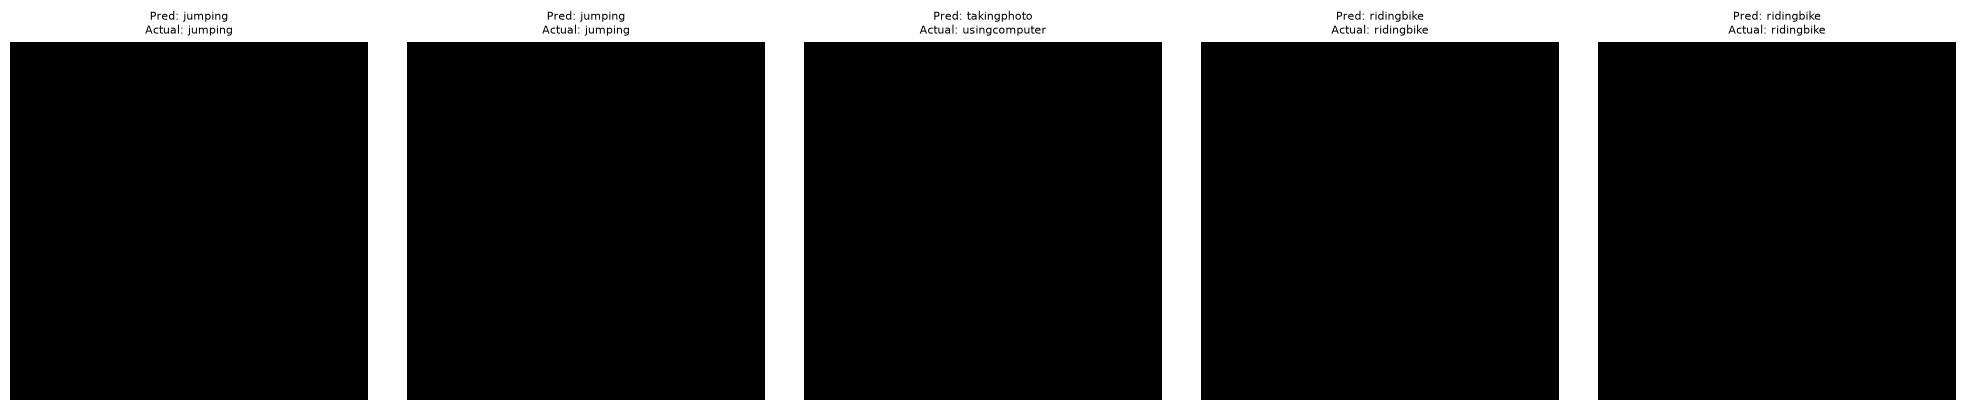

In [9]:
# Evaluate the trained MobileNetV2 model
val_predictions = mobilenet_model.predict(X_val, verbose=0)
val_pred_labels = np.argmax(val_predictions, axis=1)

print(classification_report(y_val, val_pred_labels, target_names=action_classes))
print('Confusion matrix:')
print(confusion_matrix(y_val, val_pred_labels))

# Show predicted class for a few sample images
sample_indices = np.random.choice(len(X_val), size=5, replace=False)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, idx in zip(axes, sample_indices):
    image_arr = np.clip(X_val[idx], 0, 255).astype(np.uint8)
    pred_idx = int(np.argmax(val_predictions[idx]))
    actual_idx = int(y_val[idx])
    ax.imshow(image_arr)
    ax.set_title(f'Pred: {action_classes[pred_idx]}\nActual: {action_classes[actual_idx]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Summary

This notebook uses a Pretrained MobileNetV2 transfer-learning pipeline. The same dataset and image-generation process are kept, but the model is trained using a pretrained MobileNetV2 backbone for image recognition and action classification.